# 12 · Q3 weather: correlation and lag

Statewide daily units vs average store weather. n is only the days in September, so correlations are suggestive, not statistically strong.

In [1]:
import os
import pandas as pd
import numpy as np

DATA_DIR = next(d for d in ('data', '../data', '../../data') if os.path.isdir(d))
MISSING_TOKENS = {'', 'null', 'n/a', 'na', 'nan', 'none'}
DECISION_LOG = []

def log_decision(step, decision, rows_touched, rows_before=None, rows_after=None):
    DECISION_LOG.append({'step': step, 'decision': decision, 'rows_touched': int(rows_touched),
                         'rows_before': rows_before, 'rows_after': rows_after})


In [2]:
CATEGORY_MAP = {
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'snacks': 'Snacks',
}
TS_FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
              '%d-%b-%Y %H:%M', '%m-%d-%Y %H:%M:%S']

def load_transactions():
    return pd.read_csv(os.path.join(DATA_DIR, 'walmart_transactions.csv'), dtype=str)

def standardize_missing(df):
    """Strip whitespace; turn '', NULL, N/A, NaN... into real NaN."""
    out = df.copy()
    touched = 0
    for c in out.columns:
        s = out[c].str.strip()
        newly_na = s.str.lower().isin(MISSING_TOKENS) & out[c].notna()
        touched += int(newly_na.sum())
        out[c] = s.mask(newly_na)
    log_decision('missing', 'strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)', touched, len(df), len(out))
    return out

def remove_duplicates(df):
    n0 = len(df)
    out = df.drop_duplicates()
    log_decision('duplicates', 'drop exact duplicate rows (keep first)', n0 - len(out), n0, len(out))
    n1 = len(out)
    out = out.drop_duplicates('transaction_id')
    log_decision('duplicates', 'drop repeated transaction_id (keep first)', n1 - len(out), n1, len(out))
    return out

def clean_unit_price(df):
    out = df.copy()
    raw = out['unit_price']
    dollar = int(raw.str.contains('$', regex=False, na=False).sum())
    out['unit_price'] = pd.to_numeric(raw.str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
    bad = int(out['unit_price'].isna().sum() - raw.isna().sum())
    log_decision('unit_price', "remove '$', cast text -> float", dollar, len(df), len(out))
    log_decision('unit_price', 'values that still failed numeric cast -> NaN', bad, len(df), len(out))
    return out

def clean_quantity(df):
    out = df.copy()
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    n0 = len(out)
    out = out[out['quantity'] > 0]
    log_decision('quantity', 'drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed)', n0 - len(out), n0, len(out))
    return out

def parse_timestamps(df):
    out = df.copy()
    ts = pd.Series(pd.NaT, index=out.index, dtype='datetime64[ns]')
    for fmt in TS_FORMATS:
        todo = ts.isna() & out['timestamp'].notna()
        ts[todo] = pd.to_datetime(out.loc[todo, 'timestamp'], format=fmt, errors='coerce')
    unparsed = int((ts.isna() & out['timestamp'].notna()).sum())
    missing = int(out['timestamp'].isna().sum())
    out['timestamp'] = ts
    log_decision('timestamp', f'parse {len(TS_FORMATS)} mixed formats into one datetime (naive local time); {unparsed} unparseable', int(ts.notna().sum()), len(df), len(out))
    log_decision('timestamp', 'missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed', missing, len(df), len(out))
    return out

def clean_store_id(df):
    out = df.copy()
    raw = out['store_id']
    out['store_id'] = (raw.str.upper().str.replace('_', '-', regex=False)
                          .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    log_decision('store_id', "uppercase, strip, '_'/missing '-' -> canonical 'FL-###'", int((raw != out['store_id']).sum()), len(df), len(out))
    return out

def clean_category(df):
    out = df.copy()
    raw = out['category']
    out['category'] = raw.str.lower().map(CATEGORY_MAP)
    log_decision('category', f'collapse {raw.nunique()} spellings into {out["category"].nunique()} canonical categories', int((raw != out['category']).sum()), len(df), len(out))
    return out

def clean_transactions():
    DECISION_LOG.clear()
    df = load_transactions()
    for step in (standardize_missing, remove_duplicates, clean_unit_price, clean_quantity,
                 parse_timestamps, clean_store_id, clean_category):
        df = step(df)
    df['product_name_raw'] = df['product_name']
    return df.reset_index(drop=True)


In [3]:

def clean_stores():
    s = pd.read_csv(os.path.join(DATA_DIR, 'store_locations.csv'), dtype={'zip_code': str})
    n0 = len(s)
    s['store_id'] = (s['store_id'].str.strip().str.upper().str.replace('_', '-', regex=False)
                     .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    s = s.drop_duplicates('store_id').reset_index(drop=True)
    log_decision('stores', 'canonicalise store_id and drop duplicate store rows', n0 - len(s), n0, len(s))
    changed = int((s['state'] != 'FL').sum())
    s['state'] = 'FL'
    log_decision('stores', "normalise state ('Florida', 'Fla.') to 'FL'", changed, len(s), len(s))
    # Tallahassee has no coordinates; approximate city-centre values filled in (needed for the weather call)
    fill = {'FL-619': (30.4383, -84.2807)}
    for sid, (lat, lon) in fill.items():
        m = (s['store_id'] == sid) & s['latitude'].isna()
        s.loc[m, ['latitude', 'longitude']] = (lat, lon)
    log_decision('stores', 'fill missing lat/lon for Tallahassee (FL-619) with approximate city-centre coordinates', len(fill), len(s), len(s))
    return s


In [4]:
import time, requests

WEATHER_URL = 'https://archive-api.open-meteo.com/v1/archive'
WEATHER_VARS = ['temperature_2m', 'wind_speed_10m', 'wind_gusts_10m', 'precipitation', 'pressure_msl']

def fetch_weather(lat, lon, start, end, retries=4, backoff=2):
    """Hourly weather from Open-Meteo for one point. Retries with exponential backoff and fails loudly."""
    params = dict(latitude=lat, longitude=lon, start_date=start, end_date=end,
                  hourly=','.join(WEATHER_VARS), timezone='UTC')   # request UTC, convert ourselves
    last = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(WEATHER_URL, params=params, timeout=30)
            r.raise_for_status()
            df = pd.DataFrame(r.json()['hourly']).rename(columns={'time': 'time_utc'})
            df['time_utc'] = pd.to_datetime(df['time_utc'])
            df['time_local'] = (df['time_utc'].dt.tz_localize('UTC')
                                .dt.tz_convert('America/New_York').dt.tz_localize(None))
            df['source'] = 'open-meteo-archive'
            return df
        except (requests.RequestException, KeyError, ValueError) as e:
            last = e
            print(f'attempt {attempt}/{retries} failed: {e}')
            time.sleep(backoff ** attempt)
    raise RuntimeError(f'weather API failed after {retries} attempts: {last}')


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

tx_clean = clean_transactions()
dated = tx_clean.dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
print('rows used (have a timestamp):', len(dated), 'of', len(tx_clean))


rows used (have a timestamp): 24521 of 25402


In [6]:
# Windows. Landfall (Hurricane Helene, Big Bend, FL) was the night of Sept 26, 2024 (external fact, not in the data).
# Baseline = Sept 1-15: daily orders sit flat at ~580 before the first step-up on Sept 16.
# Surge   = the 7 days before landfall day: Sept 19-25.
BASELINE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))

daily_cat = dated.groupby(['day', 'category'])['quantity'].sum().unstack(fill_value=0)
base = daily_cat.loc[BASELINE[0]:BASELINE[1]].mean()
surge = daily_cat.loc[SURGE[0]:SURGE[1]].mean()
q1 = pd.DataFrame({'baseline_avg_units': base, 'surge_avg_units': surge})
q1['multiple'] = q1['surge_avg_units'] / q1['baseline_avg_units']
q1['pct_increase'] = (q1['multiple'] - 1) * 100
q1 = q1.sort_values('pct_increase', ascending=False).round(2)

tot_base, tot_surge = daily_cat.loc[BASELINE[0]:BASELINE[1]].sum(axis=1).mean(), daily_cat.loc[SURGE[0]:SURGE[1]].sum(axis=1).mean()
q1_multiple = tot_surge / tot_base
print(f'baseline window: {BASELINE[0].date()} to {BASELINE[1].date()} ({(BASELINE[1]-BASELINE[0]).days+1} days)')
print(f'surge window:    {SURGE[0].date()} to {SURGE[1].date()} ({(SURGE[1]-SURGE[0]).days+1} days)')
print(f'all categories: {tot_base:.0f} units/day -> {tot_surge:.0f} units/day = {q1_multiple:.2f}x')
q1


baseline window: 2024-09-01 to 2024-09-15 (15 days)
surge window:    2024-09-19 to 2024-09-25 (7 days)
all categories: 1103 units/day -> 2712 units/day = 2.46x


,baseline_avg_units,surge_avg_units,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94


In [7]:
stores = clean_stores()
frames = []
for r in stores.itertuples():
    w = fetch_weather(r.latitude, r.longitude, '2024-08-31', '2024-10-01')
    w.insert(0, 'store_id', r.store_id)
    frames.append(w)
weather = pd.concat(frames, ignore_index=True)
weather = weather[(weather['time_local'] >= '2024-09-01') & (weather['time_local'] < '2024-10-01')]
print('data source:', weather['source'].unique().tolist(), '(live API call, no fallback file used)')

wx_daily = (weather.assign(day=weather['time_local'].dt.normalize())
            .groupby(['store_id', 'day'])
            .agg(max_gust=('wind_gusts_10m', 'max'), mean_wind=('wind_speed_10m', 'mean'),
                 total_precip=('precipitation', 'sum'), min_pressure=('pressure_msl', 'min'))
            .reset_index())
sales_sd = dated.groupby(['store_id', 'day'])['quantity'].sum().rename('units').reset_index()
merged = sales_sd.merge(wx_daily, on=['store_id', 'day'], how='left', validate='one_to_one')
print(f'join rows: sales store-days {len(sales_sd)} -> after join {len(merged)}; unmatched weather: {int(merged["max_gust"].isna().sum())}')
q3_join_rows_preserved = len(merged) == len(sales_sd) and merged['max_gust'].notna().all()
assert q3_join_rows_preserved
merged.head()


data source: ['open-meteo-archive'] (live API call, no fallback file used)
join rows: sales store-days 360 -> after join 360; unmatched weather: 0


,store_id,day,units,max_gust,mean_wind,total_precip,min_pressure
0,FL-078,2024-09-01,77,34.6,6.945833,1.5,1011.9
1,FL-078,2024-09-02,103,27.4,4.837500,2.9,1011.9
2,FL-078,2024-09-03,101,35.6,8.066667,8.0,1013.9
3,FL-078,2024-09-04,84,34.2,11.279167,15.6,1016.8
4,FL-078,2024-09-05,90,29.2,5.937500,13.3,1015.4


days in correlation: 30
overall units vs weather (Pearson):
max_gust        0.22
mean_wind       0.29
total_precip   -0.32
min_pressure   -0.24
dtype: float64


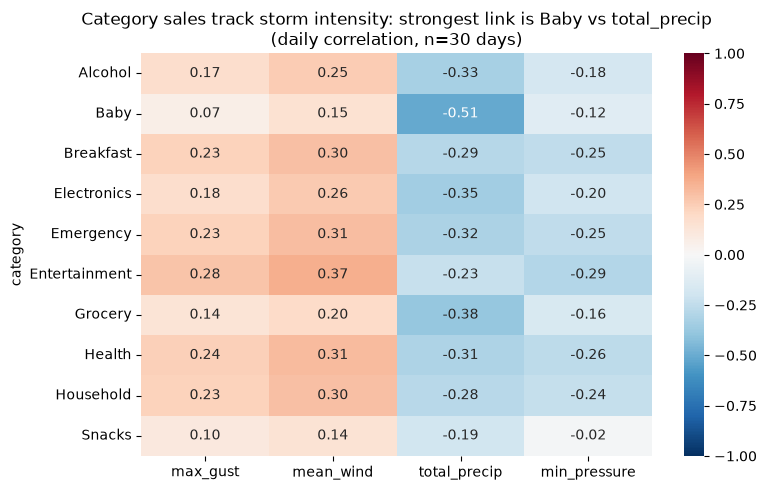

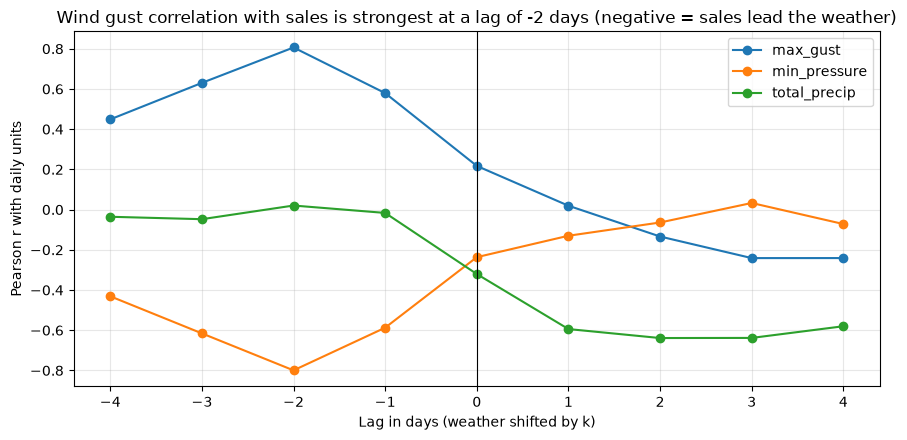

peak wind gust day: 2024-09-26 | peak sales day: 2024-09-25
    max_gust  min_pressure  total_precip
-4      0.45         -0.43         -0.04
-3      0.63         -0.62         -0.05
-2      0.81         -0.80          0.02
-1      0.58         -0.59         -0.02
 0      0.22         -0.24         -0.32
 1      0.02         -0.13         -0.59
 2     -0.13         -0.06         -0.64
 3     -0.24          0.03         -0.64
 4     -0.24         -0.07         -0.58


In [8]:
# statewide daily series: total units vs average-across-stores weather
state = merged.groupby('day').agg(units=('units', 'sum'), max_gust=('max_gust', 'mean'), mean_wind=('mean_wind', 'mean'),
                                  total_precip=('total_precip', 'mean'), min_pressure=('min_pressure', 'mean'))
n_days = len(state)
ind = ['max_gust', 'mean_wind', 'total_precip', 'min_pressure']
print('days in correlation:', n_days)
print('overall units vs weather (Pearson):'); print(state[ind].corrwith(state['units']).round(2))

heat = pd.DataFrame({i: daily_cat.corrwith(state[i]) for i in ind})
top_cell = heat.abs().stack().idxmax()
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title(f'Category sales track storm intensity: strongest link is {top_cell[0]} vs {top_cell[1]}\n(daily correlation, n={n_days} days)')
plt.tight_layout(); plt.show()

# lag: corr(units on day t, weather on day t-k). k>0: weather leads sales; k<0: sales lead weather
lags = range(-4, 5)
lag_corr = pd.DataFrame({i: [state['units'].corr(state[i].shift(k)) for k in lags] for i in ('max_gust', 'min_pressure', 'total_precip')}, index=list(lags))
best = lag_corr['max_gust'].abs().idxmax()
fig, ax = plt.subplots(figsize=(9, 4.5))
lag_corr.plot(ax=ax, marker='o'); ax.axvline(0, color='k', lw=.8)
ax.set_title(f'Wind gust correlation with sales is strongest at a lag of {best:+d} days (negative = sales lead the weather)')
ax.set_xlabel('Lag in days (weather shifted by k)'); ax.set_ylabel('Pearson r with daily units'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print('peak wind gust day:', state['max_gust'].idxmax().date(), '| peak sales day:', state['units'].idxmax().date())
print(lag_corr.round(2))
